# Diplomatura en Ciencia de Datos, Inteligencia Artificial y sus Aplicaciones en Economía y Negocios (FCE–FaMAF, UNC) — Edición 2026
## Actividad Integradora Final · Base 10 (PaySim): detección de fraude en pagos móviles P2P
### Notebook 1 de 2 — Encuadre, análisis exploratorio y curación de datos

**Grupo 21:** María Belén Silvano Ruata · Hector Eduardo Perez · Facundo Villena

**Datos:** `p2p.csv` (PaySim; Lopez-Rojas, Elmir y Axelsson, 2016): 6.362.620 transacciones simuladas de una billetera móvil en 743 horas.

**Ejecución:** *Run All*. Busca `p2p.csv` en `Fraud/` o `Fraud/datos/` y genera `datos/processed/base_curada_paysim.parquet` para el Notebook 2. Requiere `pandas`, `numpy`, `scipy`, `pyarrow` y `plotly` (`kaleido`, opcional, exporta PNG). Toda cifra se calcula en la celda que la muestra.

| Ítem de la consigna | Sección |
| :--- | :--- |
| Perfil del cliente (Integración Gerencial) y propuesta de valor (Huete) | 1 |
| Objetivos | 1.4 |
| Preguntas previas sobre los datos | 2 |
| Análisis exploratorio | 4 a 9 |
| Limpieza y resumen de decisiones | 5, 7 y 10 |

## Sección 1. Encuadre de negocio

### 1.1 Organización y oportunidad
**PagoDirecto** es una billetera móvil ficticia que reproduce PaySim. Su valor es la inmediatez, y eso mismo explota el fraude por toma de cuenta: el atacante transfiere el saldo (`TRANSFER`) y lo retira en efectivo (`CASH_OUT`) antes de que nadie reaccione. La oportunidad es reemplazar la regla vigente, que casi no detecta fraude (sección 9.2), por un sistema que decida al autorizar.

### 1.2 Perfil del cliente (Modelo de Integración Gerencial)
Cliente: el **área de Riesgo y Prevención de Fraude**. Beneficiario final: el usuario, que quiere rapidez y seguridad.

| Área | Necesidad | Traducción en el proyecto |
| :--- | :--- | :--- |
| **Operaciones** | Decidir al autorizar, con una cola de alertas revisable | Capacidad diaria de revisión y latencia medida |
| **Marketing** | No bloquear clientes honestos | Costo explícito por falso positivo |
| **Recursos Humanos** | Alertas precisas y explicables | Modelos interpretables y política de tres niveles |

### 1.3 Aporte a la propuesta de valor (Huete)
$$\text{Valor percibido} = \frac{\text{Prestación} + \text{Emoción}}{\text{Precio} + \text{Incomodidades} + \text{Inseguridades}}$$

El sistema actúa sobre el denominador: cada fraude no detectado suma **inseguridad** y cada cliente honesto bloqueado suma **incomodidad**. Como no se pueden eliminar ambas a la vez, el equilibrio se fija con una función de costo (Notebook 2).

### 1.4 Objetivos
**General.** Estimar, al autorizar y con información disponible en ese instante, la probabilidad de fraude de cada transacción P2P y convertirla en una política que maximice el ahorro neto.

**Específicos.** (1) Auditar la calidad de los datos y separar el comportamiento del fraude de los artefactos del simulador. (2) Construir atributos *ex ante*, sin fuga de información. (3) Comparar modelos con validación temporal y una regla de selección declarada de antemano. (4) Fijar el umbral con una función de costo, medir su sensibilidad, evaluar en un período posterior y documentar qué decisiones se tomaron después de observarlo.

### 1.5 Supuestos de diseño (no surgen de los datos)
| Supuesto | Valor base | Uso |
| :--- | :--- | :--- |
| Costo de revisar una alerta | 1.500 u.m. | Función económica |
| Fricción por cliente honesto bloqueado | 8.500 u.m. | Función económica |
| Capacidad de revisión | 1.000 alertas por día | Restricción operativa |
| Recupero de un fraude detectado | 100% del monto | Función económica |

El Notebook 2 mide cuánto cambian las conclusiones si se modifican.

## Sección 2. Preguntas previas sobre los datos y el problema

**¿De qué tratan los datos?** 6.362.620 operaciones generadas por PaySim, un simulador calibrado con registros reales de dinero móvil. Cada fila trae la hora (`step`), el tipo, el monto, los saldos antes y después, las cuentas, la etiqueta de fraude y la bandera de la regla vigente. Algunas regularidades pueden ser del programa y no del fraude real.

**¿Qué tipo de problema es?** Clasificación binaria supervisada con desbalance severo.

**¿Es una serie temporal?** Hay orden temporal, pero no se pronostica una serie: se clasifica cada operación. El tiempo se respeta entrenando con el pasado, evaluando con el futuro y calculando el historial solo con datos anteriores.

**¿Para qué sirve?** Para frenar transferencias fraudulentas antes de que el dinero salga, sin bloquear a clientes honestos.

**¿Cómo se usan las predicciones?** Cada operación recibe un puntaje al autorizar; dos umbrales lo traducen en aprobar, pedir verificación o retener y derivar a un analista.

## Sección 3. Configuración del entorno y reproducibilidad
La celda siguiente fija la semilla, detecta la raíz del proyecto (las rutas que se imprimen son relativas, para no exponer rutas locales), define el estilo de los gráficos interactivos y las funciones auxiliares de formato y de intervalos de Wilson.

In [1]:
# Configuración común: librerías, semilla, rutas portables, estilo gráfico y utilidades
import sys, time, platform, warnings, json
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
import scipy.stats as stats
import plotly
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from IPython.display import display, Markdown

SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)

# Raíz del proyecto: funciona tanto si el notebook se ejecuta desde notebooks/ como desde la raíz
_AQUI = Path.cwd().resolve()
BASE_DIR = _AQUI.parent if _AQUI.name == "notebooks" else _AQUI
OUTPUTS_DIR = BASE_DIR / "reports"
FIG_DIR, TAB_DIR, MOD_DIR = OUTPUTS_DIR / "figures", OUTPUTS_DIR / "tables", OUTPUTS_DIR / "models"
DATA_PROC_DIR = BASE_DIR / "data" / "processed"
for _p in (FIG_DIR, TAB_DIR, MOD_DIR, DATA_PROC_DIR):
    _p.mkdir(parents=True, exist_ok=True)

def ruta_rel(p):
    """Ruta relativa a la raíz del proyecto (evita exponer rutas locales del usuario)."""
    p = Path(p).resolve()
    try:
        return p.relative_to(BASE_DIR).as_posix()
    except ValueError:
        return p.name

# Paleta institucional (se conserva la identidad visual del trabajo)
COLOR_FRAUD, COLOR_LEGIT, COLOR_NEUTRAL, COLOR_ACCENT, COLOR_OK = "#B00020", "#1B365D", "#5C768D", "#D97706", "#0F766E"
pio.templates["mai"] = go.layout.Template(layout=go.Layout(
    font=dict(family="Arial, Helvetica, sans-serif", size=13, color="#1F2937"),
    title=dict(font=dict(size=16), x=0.0, xanchor="left"),
    plot_bgcolor="white", paper_bgcolor="white",
    xaxis=dict(showgrid=True, gridcolor="#E5E7EB", zeroline=False, linecolor="#9CA3AF"),
    yaxis=dict(showgrid=True, gridcolor="#E5E7EB", zeroline=False, linecolor="#9CA3AF"),
    legend=dict(bgcolor="rgba(255,255,255,0.8)"), hovermode="closest",
    separators=",.",  # convención rioplatense: coma decimal, punto de miles
))
pio.templates.default = "simple_white+mai"

# Renderizado: interactivo en Jupyter/VS Code; si kaleido está instalado se agrega una copia estática (PNG)
try:
    import kaleido  # noqa: F401
    _PNG_OK = True
except ImportError:
    _PNG_OK = False
pio.renderers.default = "plotly_mimetype+notebook_connected" + ("+png" if _PNG_OK else "")
if _PNG_OK:
    pio.renderers["png"].width, pio.renderers["png"].height = 1100, 520

def guardar_fig(fig, nombre):
    """Guarda la figura interactiva (HTML) y, si es posible, su versión estática (PNG) para el informe."""
    fig.write_html(FIG_DIR / f"{nombre}.html", include_plotlyjs="cdn")
    destino = f"{ruta_rel(FIG_DIR / nombre)}.html"
    if _PNG_OK:
        fig.write_image(FIG_DIR / f"{nombre}.png", width=1100, height=520, scale=2)
        destino += " y .png"
    print(f"Figura guardada en {destino}")

# Formato numérico rioplatense para los textos impresos
def f_int(x):
    return f"{int(round(x)):,}".replace(",", ".")

def f_num(x, d=2):
    return f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def f_pct(x, d=2):
    """x es una proporción (0-1)."""
    return f_num(100 * x, d) + "%"

def f_p(p):
    return "< 1e-300" if p == 0 else f"{p:.2e}"

def wilson(k, n, conf=0.95):
    """Intervalo de Wilson para una proporción binomial (apto para eventos raros)."""
    if n == 0:
        return (0.0, 0.0)
    z = stats.norm.ppf(1 - (1 - conf) / 2)
    p = k / n
    den = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / den
    semi = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return (max(0.0, centro - semi), min(1.0, centro + semi))

print(f"Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | "
      f"SciPy {scipy.__version__} | Plotly {plotly.__version__} | exportación PNG: {'sí' if _PNG_OK else 'no (instalar kaleido)'}")
print(f"Raíz del proyecto detectada: {BASE_DIR.name}/  |  semilla global: {SEED}")

Python 3.13.18 | pandas 3.0.5 | NumPy 2.5.3 | SciPy 1.18.1 | Plotly 7.1.0 | exportación PNG: sí
Raíz del proyecto detectada: Fraud/  |  semilla global: 42


## Sección 4. Ingesta de datos y diccionario de variables
Los montos y saldos se leen en `float64`. La decisión no es estética: en `float32` (24 bits de mantisa) los números mayores a 131.072 ya no pueden representar centavos, y el análisis de la firma de vaciamiento y de la consistencia contable depende de comparar montos al centavo. La celda 4.2 cuantifica cuántas operaciones se habrían distorsionado.

In [2]:
# 4.1 Lectura del archivo original con tipos explícitos y controles de integridad
RUTAS_POSIBLES = [BASE_DIR / "data" / "raw" / "p2p.csv", BASE_DIR / "p2p.csv", BASE_DIR / "datos" / "p2p.csv", BASE_DIR / "datos" / "raw" / "p2p.csv"]
ruta_csv = next((r for r in RUTAS_POSIBLES if r.exists()), None)
if ruta_csv is None:
    raise FileNotFoundError("No se encontró p2p.csv: ubicarlo en la raíz del proyecto o en la carpeta datos/.")

COLUMNAS = ["step", "type", "amount", "nameOrig", "oldbalanceOrg", "newbalanceOrig",
            "nameDest", "oldbalanceDest", "newbalanceDest", "isFraud", "isFlaggedFraud"]
DTYPES = {"step": "int16", "type": "category", "nameOrig": "string", "nameDest": "string",
          "isFraud": "int8", "isFlaggedFraud": "int8",
          "amount": "float64", "oldbalanceOrg": "float64", "newbalanceOrig": "float64",
          "oldbalanceDest": "float64", "newbalanceDest": "float64"}

t0 = time.perf_counter()
df = pd.read_csv(ruta_csv, dtype=DTYPES)
t_carga = time.perf_counter() - t0

assert list(df.columns) == COLUMNAS, "El archivo no tiene el esquema esperado"
assert set(df["isFraud"].unique()) <= {0, 1} and set(df["isFlaggedFraud"].unique()) <= {0, 1}

N_TOTAL = len(df)
N_FRAUDE = int(df["isFraud"].sum())
print(f"Archivo leído: {ruta_rel(ruta_csv)} en {f_num(t_carga, 1)} s")
print(f"Dimensiones: {f_int(N_TOTAL)} filas x {df.shape[1]} columnas | memoria: {f_num(df.memory_usage(deep=True).sum() / 2**20, 1)} MB")
print(f"Rango temporal: step {df['step'].min()} a {df['step'].max()} ({df['step'].nunique()} horas distintas, "
      f"{(df['step'].max() - 1) // 24 + 1} días)")
print(f"Fraudes etiquetados: {f_int(N_FRAUDE)} ({f_pct(N_FRAUDE / N_TOTAL, 3)} del total)")
display(df.head())

Archivo leído: p2p.csv en 6,9 s
Dimensiones: 6.362.620 filas x 11 columnas | memoria: 497,3 MB
Rango temporal: step 1 a 743 (743 horas distintas, 31 días)
Fraudes etiquetados: 8.213 (0,129% del total)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [3]:
# 4.2 Por qué float64: cuántos montos pierden sus centavos si se almacenan en float32
cent_64 = np.round(df["amount"].to_numpy() * 100).astype(np.int64)
cent_32 = np.round(df["amount"].to_numpy().astype(np.float32).astype(np.float64) * 100).astype(np.int64)
pct_distorsion = (cent_64 != cent_32).mean()
print(f"Operaciones cuyo monto cambia al centavo al pasar a float32: {f_int((cent_64 != cent_32).sum())} "
      f"({f_pct(pct_distorsion, 1)}). Por eso se conserva float64 en toda la base curada.")
del cent_64, cent_32

Operaciones cuyo monto cambia al centavo al pasar a float32: 1.306.385 (20,5%). Por eso se conserva float64 en toda la base curada.


### Diccionario de variables y momento en que la información está disponible
La columna *Disponibilidad* responde a la pregunta clave de un sistema que decide en línea: ¿se conoce este dato en el instante en que el cliente pulsa "transferir"? Solo lo *ex ante* puede usarse como predictor.

| Atributo | Tipo | Descripción | Disponibilidad |
| :--- | :--- | :--- | :--- |
| `step` | entero | Hora de la simulación (1 a 743). | Ex ante |
| `type` | categórica | `CASH_IN`, `CASH_OUT`, `DEBIT`, `PAYMENT`, `TRANSFER`. | Ex ante |
| `amount` | real | Monto de la operación en unidades monetarias (u.m.). | Ex ante |
| `nameOrig` | texto | Cuenta de origen. | Ex ante (identificador, no predictor) |
| `oldbalanceOrg` | real | Saldo de origen antes de la operación. | Ex ante |
| `newbalanceOrig` | real | Saldo de origen después de la operación. | **Ex post: excluido** |
| `nameDest` | texto | Cuenta de destino; prefijo `C` cliente, `M` comercio. | Ex ante (se usa para construir historial) |
| `oldbalanceDest` | real | Saldo de destino antes de la operación. | Ex ante |
| `newbalanceDest` | real | Saldo de destino después de la operación. | **Ex post: excluido** |
| `isFraud` | binaria | Etiqueta de fraude (variable objetivo). | Supervisión |
| `isFlaggedFraud` | binaria | Bandera de la regla vigente. La documentación de PaySim la describe como "transferencias mayores a 200.000 u.m."; su comportamiento real se audita en la sección 9.2. | Línea de base |

## Sección 5. Auditoría de calidad de datos
Se revisan seis ejes: completitud, unicidad, validez de rangos, ceros estructurales, consistencia contable y disponibilidad temporal de la información.

In [4]:
# 5.1 Completitud y unicidad
nulos = df.isna().sum()
dup_exactos = int(df.duplicated().sum())
CLAVE = ["step", "nameOrig", "nameDest", "amount"]
dup_clave = int(df.duplicated(subset=CLAVE).sum())
n_orig, n_dest = df["nameOrig"].nunique(), df["nameDest"].nunique()

calidad = pd.DataFrame({
    "Control": ["Valores nulos (todas las columnas)", "Filas duplicadas exactas",
                "Duplicados por clave (step, nameOrig, nameDest, amount)",
                "Cuentas de origen distintas", "Cuentas de destino distintas"],
    "Resultado": [f_int(nulos.sum()), f_int(dup_exactos), f_int(dup_clave), f_int(n_orig), f_int(n_dest)],
})
display(calidad)
print(f"Cada cuenta de origen aparece en promedio {f_num(N_TOTAL / n_orig, 3)} veces: PaySim casi no repite emisores, "
      f"por lo que no es posible construir historial del cliente que origina la operación.")
print("Decisión 1 y 2: " + ("no hay nulos ni duplicados; no se imputa ni se elimina ninguna fila."
                            if nulos.sum() == 0 and dup_exactos == 0 and dup_clave == 0
                            else "se detectaron nulos o duplicados: revisar antes de continuar."))

,Control,Resultado
0,Valores nulos (todas las columnas),0
1,Filas duplicadas exactas,0
2,"Duplicados por clave (step, nameOrig, nameDest...",0
3,Cuentas de origen distintas,6.353.307
4,Cuentas de destino distintas,2.722.362


Cada cuenta de origen aparece en promedio 1,001 veces: PaySim casi no repite emisores, por lo que no es posible construir historial del cliente que origina la operación.
Decisión 1 y 2: no hay nulos ni duplicados; no se imputa ni se elimina ninguna fila.


In [5]:
# 5.2 Validez de rangos: mínimos, máximos, negativos y ceros por variable numérica
NUM = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
rangos = pd.DataFrame({
    "Mínimo": df[NUM].min(), "Máximo": df[NUM].max(),
    "Negativos": (df[NUM] < 0).sum(), "Ceros": (df[NUM] == 0).sum(),
})
rangos["% ceros"] = rangos["Ceros"] / N_TOTAL * 100
display(rangos.style.format({"Mínimo": "{:,.2f}", "Máximo": "{:,.2f}", "Negativos": "{:,}", "Ceros": "{:,}", "% ceros": "{:.2f}"}))

fr_all, lg_all = df[df["isFraud"] == 1], df[df["isFraud"] == 0]
n_monto0 = int((df["amount"] == 0).sum()); n_monto0_fr = int((fr_all["amount"] == 0).sum())
TOPE = 10_000_000.0
n_fr_tope, n_lg_tope = int((fr_all["amount"] == TOPE).sum()), int((lg_all["amount"] == TOPE).sum())
n_lg_sobre = int((lg_all["amount"] > TOPE).sum())
print(f"Operaciones con monto 0: {n_monto0} (fraudes: {n_monto0_fr}).")
print(f"Monto máximo en fraude: {f_num(fr_all['amount'].max())} u.m. | en legítimas: {f_num(lg_all['amount'].max())} u.m.")
print(f"Operaciones con monto exactamente igual a 10.000.000 u.m.: {f_int(n_fr_tope)} fraudes y {f_int(n_lg_tope)} legítimas; "
      f"además {f_int(n_lg_sobre)} legítimas superan ese valor.")
print("Lectura: el fraude simulado nunca supera 10.000.000 u.m. por operación, pero ese valor no es un límite del sistema "
      "(hay legítimas por encima) ni exclusivo del fraude (también hay legítimas exactamente en 10.000.000). "
      "Es una regularidad del simulador, que fracciona los montos grandes en tramos de 10 millones.")

,Mínimo,Máximo,Negativos,Ceros,% ceros
amount,0.00,"92,445,516.64",0,16,0.00
oldbalanceOrg,0.00,"59,585,040.37",0,"2,102,449",33.04
newbalanceOrig,0.00,"49,585,040.37",0,"3,609,566",56.73
oldbalanceDest,0.00,"356,015,889.35",0,"2,704,388",42.50
newbalanceDest,0.00,"356,179,278.92",0,"2,439,433",38.34


Operaciones con monto 0: 16 (fraudes: 16).
Monto máximo en fraude: 10.000.000,00 u.m. | en legítimas: 92.445.516,64 u.m.
Operaciones con monto exactamente igual a 10.000.000 u.m.: 287 fraudes y 2.920 legítimas; además 2.443 legítimas superan ese valor.
Lectura: el fraude simulado nunca supera 10.000.000 u.m. por operación, pero ese valor no es un límite del sistema (hay legítimas por encima) ni exclusivo del fraude (también hay legítimas exactamente en 10.000.000). Es una regularidad del simulador, que fracciona los montos grandes en tramos de 10 millones.


In [6]:
# 5.3 Ceros estructurales: destinos comercio ('M') frente a destinos cliente ('C')
es_m = df["nameDest"].str.startswith("M")
dest_m = df[es_m]
print(f"Operaciones hacia comercios: {f_int(len(dest_m))} ({f_pct(len(dest_m) / N_TOTAL)}); tipos: {sorted(dest_m['type'].astype(str).unique())}")
print(f"PAYMENT que van a comercios: {f_pct((df.loc[df['type'] == 'PAYMENT', 'nameDest'].str.startswith('M')).mean())}")
print(f"Saldos de destino en 0 dentro de los comercios: antes {f_pct((dest_m['oldbalanceDest'] == 0).mean())}, "
      f"después {f_pct((dest_m['newbalanceDest'] == 0).mean())}")
print(f"Fraudes con destino comercio: {int(dest_m['isFraud'].sum())}")
print("Decisión 6: los saldos en 0 de los comercios son ceros estructurales (la billetera no observa el saldo del comercio), "
      "no faltantes; no se imputan y se marca el tipo de destino con la bandera dest_es_comerciante.")

Operaciones hacia comercios: 2.151.495 (33,81%); tipos: ['PAYMENT']
PAYMENT que van a comercios: 100,00%
Saldos de destino en 0 dentro de los comercios: antes 100,00%, después 100,00%
Fraudes con destino comercio: 0
Decisión 6: los saldos en 0 de los comercios son ceros estructurales (la billetera no observa el saldo del comercio), no faltantes; no se imputan y se marca el tipo de destino con la bandera dest_es_comerciante.


In [7]:
# 5.4 Consistencia contable en el subespacio TRANSFER + CASH_OUT y explicación de la discrepancia
TOL = 0.01
riesgo_mask = df["type"].isin(["TRANSFER", "CASH_OUT"]).to_numpy()
r = df.loc[riesgo_mask, ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "isFraud"]]
cents_monto = np.round(r["amount"] * 100).astype(np.int64)
cents_saldo = np.round(r["oldbalanceOrg"] * 100).astype(np.int64)
teorico = r["oldbalanceOrg"] - r["amount"]

aud = pd.DataFrame({
    "isFraud": r["isFraud"].to_numpy(),
    "disc_ingenua": ((teorico - r["newbalanceOrig"]).abs() > TOL).to_numpy(),
    "disc_con_piso": ((teorico.clip(lower=0) - r["newbalanceOrig"]).abs() > TOL).to_numpy(),
    "monto_excede_saldo": (cents_monto > cents_saldo).to_numpy(),
    "saldo_final_cero": (r["newbalanceOrig"] == 0).to_numpy(),
    "disc_destino": ((r["oldbalanceDest"] + r["amount"] - r["newbalanceDest"]).abs() > TOL).to_numpy(),
})
tabla_contable = (aud.groupby("isFraud").mean() * 100).rename(index={0: "Legítimas", 1: "Fraudes"}).T
tabla_contable.index = ["Saldo final ≠ saldo inicial − monto",
                        "Saldo final ≠ máx(saldo inicial − monto, 0)",
                        "Monto mayor que el saldo inicial de origen",
                        "Saldo final de origen igual a 0",
                        "Saldo final de destino ≠ saldo inicial + monto"]
display(tabla_contable.round(2))
tabla_contable.to_csv(TAB_DIR / "tabla_consistencia_contable.csv")

ti = tabla_contable["Legítimas"]
print(f"En legítimas, la discrepancia aparente ({f_num(ti.iloc[0])}%) cae a {f_num(ti.iloc[1])}% cuando se reconoce que el simulador "
      f"lleva el saldo a 0 si el monto supera el saldo disponible, situación que ocurre en el {f_num(ti.iloc[2])}% de las legítimas "
      f"y solo en el {f_num(tabla_contable['Fraudes'].iloc[2])}% de los fraudes.")
print("Lectura: no se trata de asincronías contables sino de una regla del simulador. El hecho relevante para el modelo es otro: "
      "casi todas las operaciones legítimas de riesgo piden más dinero del que la cuenta tiene, y casi ningún fraude lo hace. "
      "Ese dato es ex ante (monto y saldo previo se conocen al autorizar) y se convierte en la bandera monto_excede_saldo.")
print(f"Fuga de información: el saldo final de origen es 0 en el {f_num(tabla_contable['Fraudes'].iloc[3])}% de los fraudes; "
      "usar newbalanceOrig o newbalanceDest como predictores sería usar el resultado de la operación para predecirla. Se excluyen.")

isFraud,Legítimas,Fraudes
Saldo final ≠ saldo inicial − monto,90.51,0.55
"Saldo final ≠ máx(saldo inicial − monto, 0)",0.41,0.19
Monto mayor que el saldo inicial de origen,90.10,0.35
Saldo final de origen igual a 0,90.10,98.05
Saldo final de destino ≠ saldo inicial + monto,22.58,56.50


En legítimas, la discrepancia aparente (90,51%) cae a 0,41% cuando se reconoce que el simulador lleva el saldo a 0 si el monto supera el saldo disponible, situación que ocurre en el 90,10% de las legítimas y solo en el 0,35% de los fraudes.
Lectura: no se trata de asincronías contables sino de una regla del simulador. El hecho relevante para el modelo es otro: casi todas las operaciones legítimas de riesgo piden más dinero del que la cuenta tiene, y casi ningún fraude lo hace. Ese dato es ex ante (monto y saldo previo se conocen al autorizar) y se convierte en la bandera monto_excede_saldo.
Fuga de información: el saldo final de origen es 0 en el 98,05% de los fraudes; usar newbalanceOrig o newbalanceDest como predictores sería usar el resultado de la operación para predecirla. Se excluyen.


## Sección 6. Análisis univariado y concentración del riesgo

In [8]:
# 6.1 Prevalencia de fraude por tipo de operación con intervalos de Wilson al 95%
filas = []
for t, g in df.groupby("type", observed=True):
    n, k = len(g), int(g["isFraud"].sum())
    lo, hi = wilson(k, n)
    filas.append({"Tipo": str(t), "Operaciones": n, "% del total": n / N_TOTAL * 100, "Fraudes": k,
                  "Tasa de fraude (%)": k / n * 100, "IC 95% inf (%)": lo * 100, "IC 95% sup (%)": hi * 100,
                  "Monto defraudado (u.m.)": g.loc[g["isFraud"] == 1, "amount"].sum()})
tipos = pd.DataFrame(filas).sort_values("Operaciones", ascending=False).reset_index(drop=True)
tipos.to_csv(TAB_DIR / "tabla_resumen_tipo_transaccion.csv", index=False)
display(tipos.style.format({"Operaciones": "{:,}", "% del total": "{:.2f}", "Fraudes": "{:,}", "Tasa de fraude (%)": "{:.4f}",
                            "IC 95% inf (%)": "{:.4f}", "IC 95% sup (%)": "{:.4f}", "Monto defraudado (u.m.)": "{:,.0f}"}))

N_RIESGO = int(riesgo_mask.sum())
sin_fraude = tipos.loc[tipos["Fraudes"] == 0, "Tipo"].tolist()
print(f"Los {f_int(N_FRAUDE)} fraudes ocurren solo en TRANSFER ({f_int(tipos.set_index('Tipo').loc['TRANSFER', 'Fraudes'])}) y "
      f"CASH_OUT ({f_int(tipos.set_index('Tipo').loc['CASH_OUT', 'Fraudes'])}). Los tipos {', '.join(sin_fraude)} no registran ningún fraude; "
      f"para ellos el límite superior de Wilson acota la tasa a valores ínfimos (por ejemplo, "
      f"{f_num(tipos.set_index('Tipo').loc['PAYMENT', 'IC 95% sup (%)'], 5)}% en PAYMENT).")
print(f"Decisión 11: modelar solo TRANSFER y CASH_OUT ({f_int(N_RIESGO)} operaciones, {f_pct(N_RIESGO / N_TOTAL)} del total), "
      f"lo que reduce en {f_pct(1 - N_RIESGO / N_TOTAL)} el volumen a evaluar sin excluir ningún fraude.")
print(f"Prevalencia dentro del subespacio de riesgo: {f_pct(N_FRAUDE / N_RIESGO, 3)} (1 fraude cada {f_int(N_RIESGO / N_FRAUDE)} operaciones).")

,Tipo,Operaciones,% del total,Fraudes,Tasa de fraude (%),IC 95% inf (%),IC 95% sup (%),Monto defraudado (u.m.)
0,CASH_OUT,"2,237,500",35.17,"4,116",0.1840,0.1784,0.1897,"5,989,202,244"
1,PAYMENT,"2,151,495",33.81,0,0.0000,0.0000,0.0002,0
2,CASH_IN,"1,399,284",21.99,0,0.0000,0.0000,0.0003,0
3,TRANSFER,"532,909",8.38,"4,097",0.7688,0.7457,0.7926,"6,067,213,184"
4,DEBIT,"41,432",0.65,0,0.0000,0.0000,0.0093,0


Los 8.213 fraudes ocurren solo en TRANSFER (4.097) y CASH_OUT (4.116). Los tipos PAYMENT, CASH_IN, DEBIT no registran ningún fraude; para ellos el límite superior de Wilson acota la tasa a valores ínfimos (por ejemplo, 0,00018% en PAYMENT).
Decisión 11: modelar solo TRANSFER y CASH_OUT (2.770.409 operaciones, 43,54% del total), lo que reduce en 56,46% el volumen a evaluar sin excluir ningún fraude.
Prevalencia dentro del subespacio de riesgo: 0,296% (1 fraude cada 337 operaciones).


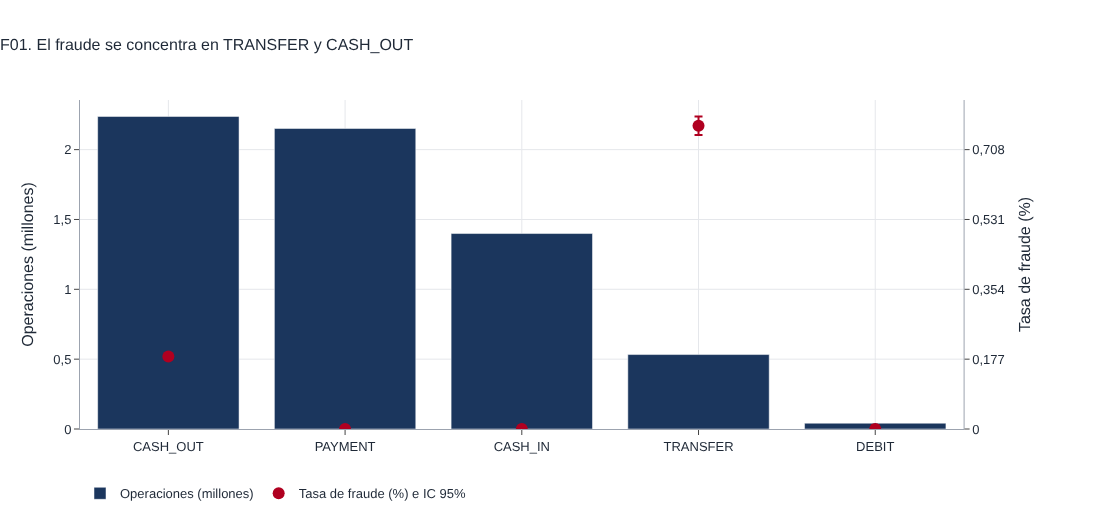

Figura guardada en outputs/figures/F01_volumen_y_tasa_por_tipo.html y .png


In [9]:
# 6.2 Figura F01: volumen y tasa de fraude por tipo (interactiva)
fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_bar(x=tipos["Tipo"], y=tipos["Operaciones"] / 1e6, name="Operaciones (millones)", marker_color=COLOR_LEGIT,
            hovertemplate="%{x}<br>%{y:.3f} millones de operaciones<extra></extra>")
fig.add_scatter(x=tipos["Tipo"], y=tipos["Tasa de fraude (%)"], mode="markers", name="Tasa de fraude (%) e IC 95%",
                marker=dict(color=COLOR_FRAUD, size=12),
                error_y=dict(type="data", symmetric=False, array=tipos["IC 95% sup (%)"] - tipos["Tasa de fraude (%)"],
                             arrayminus=tipos["Tasa de fraude (%)"] - tipos["IC 95% inf (%)"]),
                customdata=tipos[["Fraudes"]], hovertemplate="%{x}<br>Tasa: %{y:.4f}%<br>Fraudes: %{customdata[0]:,}<extra></extra>",
                secondary_y=True)
fig.update_layout(title="F01. El fraude se concentra en TRANSFER y CASH_OUT", legend=dict(orientation="h", y=-0.15), height=480)
fig.update_yaxes(title_text="Operaciones (millones)", secondary_y=False)
fig.update_yaxes(title_text="Tasa de fraude (%)", secondary_y=True, showgrid=False, rangemode="tozero")
fig.show()
guardar_fig(fig, "F01_volumen_y_tasa_por_tipo")

In [10]:
# 6.3 Estadísticos descriptivos paramétricos y robustos por clase, en el subespacio de riesgo
df_riesgo = df.loc[riesgo_mask].copy()
fr, lg = df_riesgo[df_riesgo["isFraud"] == 1], df_riesgo[df_riesgo["isFraud"] == 0]

def descriptivos(s):
    q1, med, q3, p99 = s.quantile([0.25, 0.5, 0.75, 0.99])
    return pd.Series({"n": len(s), "media": s.mean(), "desvío": s.std(), "mediana": med, "Q1": q1, "Q3": q3,
                      "IQR": q3 - q1, "P99": p99, "máximo": s.max(), "asimetría": s.skew(), "curtosis": s.kurt()})

desc = pd.concat({(v, c): descriptivos(g[v]) for v in ["amount", "oldbalanceOrg", "oldbalanceDest"]
                  for c, g in [("Fraude", fr), ("Legítima", lg)]}, axis=1)
desc.to_csv(TAB_DIR / "tabla_estadisticos_descriptivos.csv")
display(desc.style.format("{:,.2f}"))
print(f"Monto: la media legítima ({f_num(lg['amount'].mean(), 0)}) es {f_num(lg['amount'].mean() / lg['amount'].median(), 1)} veces su mediana ({f_num(lg['amount'].median(), 0)}) "
      f"y la asimetría es {f_num(lg['amount'].skew(), 1)}: las distribuciones son muy asimétricas, por lo que se priorizan "
      "mediana, IQR y percentiles, y en el modelado se usan transformaciones logarítmicas.")
print(f"Saldo de origen: mediana {f_num(fr['oldbalanceOrg'].median(), 0)} u.m. en fraudes frente a {f_num(lg['oldbalanceOrg'].median(), 0)} u.m. "
      f"en legítimas; el {f_pct((lg['oldbalanceOrg'] == 0).mean(), 1)} de las legítimas parte de saldo 0, contra el "
      f"{f_pct((fr['oldbalanceOrg'] == 0).mean(), 2)} de los fraudes.")

Monto: la media legítima (314.115) es 1,8 veces su mediana (171.034) y la asimetría es 22,6: las distribuciones son muy asimétricas, por lo que se priorizan mediana, IQR y percentiles, y en el modelado se usan transformaciones logarítmicas.
Saldo de origen: mediana 438.983 u.m. en fraudes frente a 283 u.m. en legítimas; el 47,4% de las legítimas parte de saldo 0, contra el 0,50% de los fraudes.


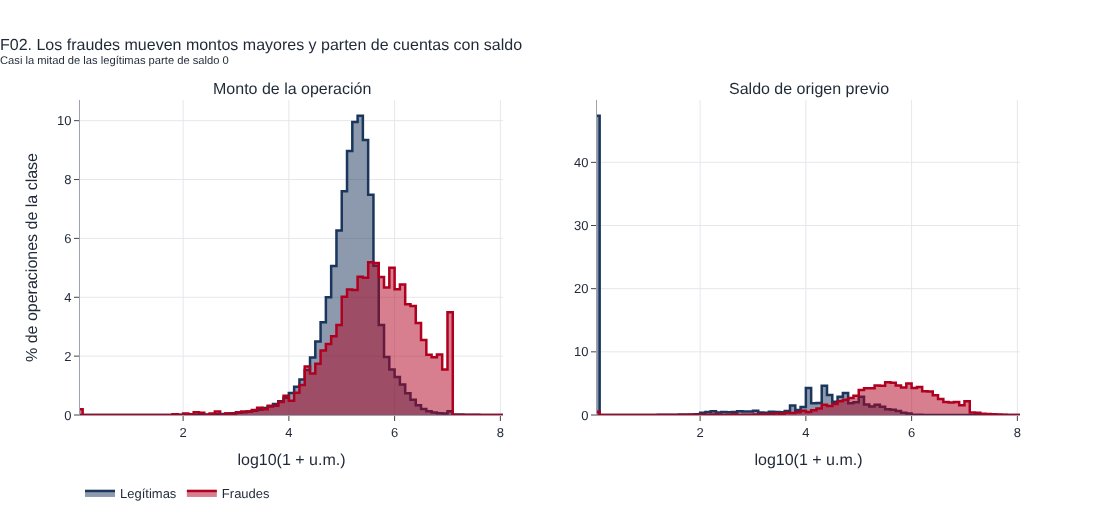

Figura guardada en outputs/figures/F02_distribucion_monto_saldo.html y .png


In [11]:
# 6.4 Figura F02: distribución del monto y del saldo de origen por clase (escala log10(1 + x))
fig = make_subplots(rows=1, cols=2, subplot_titles=("Monto de la operación", "Saldo de origen previo"))
bins = np.linspace(0, 8.1, 82)
for j, var in enumerate(["amount", "oldbalanceOrg"], start=1):
    for nombre, g, col in [("Legítimas", lg, COLOR_LEGIT), ("Fraudes", fr, COLOR_FRAUD)]:
        h, e = np.histogram(np.log10(1 + g[var].to_numpy()), bins=bins)
        fig.add_scatter(x=(e[:-1] + e[1:]) / 2, y=h / h.sum() * 100, mode="lines", line=dict(color=col, width=2.5, shape="hvh"),
                        fill="tozeroy", opacity=0.6, name=nombre, legendgroup=nombre, showlegend=(j == 1),
                        hovertemplate=f"{nombre}<br>log10(1+x)=%{{x:.2f}}<br>%{{y:.2f}}% de la clase<extra></extra>", row=1, col=j)
    fig.update_xaxes(title_text="log10(1 + u.m.)", row=1, col=j)
fig.update_yaxes(title_text="% de operaciones de la clase", row=1, col=1)
fig.update_layout(title="F02. Los fraudes mueven montos mayores y parten de cuentas con saldo<br><sup>Casi la mitad de las legítimas parte de saldo 0</sup>", margin=dict(t=100, b=90),
                  height=460, legend=dict(orientation="h", y=-0.2))
fig.show()
guardar_fig(fig, "F02_distribucion_monto_saldo")

## Sección 7. Análisis bivariado: contrastes, firma de vaciamiento y valores extremos
### 7.1 Contrastes no paramétricos con tamaño del efecto
Con millones de observaciones casi toda diferencia es significativa, así que se reporta también el tamaño del efecto: la **correlación biserial de rangos** $r = 2U/(n_1 n_2) - 1$ y el estadístico $D$ de Kolmogorov-Smirnov ($\alpha = 0{,}01$; $|r|$ < 0,1 trivial, 0,1–0,3 pequeño, 0,3–0,5 mediano, ≥ 0,5 grande). Se usan todas las observaciones.

In [12]:
# 7.1 Mann-Whitney U y Kolmogorov-Smirnov sobre la población completa del subespacio de riesgo
ALFA = 0.01
def magnitud(r_abs):
    return "trivial" if r_abs < 0.1 else "pequeña" if r_abs < 0.3 else "mediana" if r_abs < 0.5 else "grande"

res = []
for var in ["amount", "oldbalanceOrg", "oldbalanceDest"]:
    x, y = fr[var].to_numpy(), lg[var].to_numpy()
    u, p_u = stats.mannwhitneyu(x, y, alternative="two-sided", method="asymptotic")
    r_rb = 2 * u / (len(x) * len(y)) - 1
    ks = stats.ks_2samp(x, y, method="asymp")
    concl_u = "Rechaza H0" if p_u < ALFA else "No rechaza H0"
    concl_ks = "Rechaza H0" if ks.pvalue < ALFA else "No rechaza H0"
    res.append({"Variable": var, "Mediana fraude": np.median(x), "Mediana legítima": np.median(y),
                "p-valor U": f_p(p_u), "r biserial de rangos": r_rb, "Magnitud": magnitud(abs(r_rb)),
                "KS D": ks.statistic, "p-valor KS": f_p(ks.pvalue),
                "Conclusión (α = 0,01)": f"U: {concl_u}; KS: {concl_ks}"})
pruebas = pd.DataFrame(res)
pruebas.to_csv(TAB_DIR / "tabla_pruebas_hipotesis_no_parametricas.csv", index=False)
display(pruebas.style.format({"Mediana fraude": "{:,.0f}", "Mediana legítima": "{:,.0f}", "r biserial de rangos": "{:+.3f}", "KS D": "{:.3f}"}))
for _, f in pruebas.iterrows():
    sentido = "mayores" if f["r biserial de rangos"] > 0 else "menores"
    print(f"{f['Variable']}: {f['Conclusión (α = 0,01)']}. Los fraudes tienden a valores {sentido} (r = {f_num(f['r biserial de rangos'], 3)}, "
          f"efecto {f['Magnitud']}; D = {f_num(f['KS D'], 3)}).")

,Variable,Mediana fraude,Mediana legítima,p-valor U,r biserial de rangos,Magnitud,KS D,p-valor KS,"Conclusión (α = 0,01)"
0,amount,"441,423","171,034",< 1e-300,+0.367,mediana,0.363,< 1e-300,U: Rechaza H0; KS: Rechaza H0
1,oldbalanceOrg,"438,983",283,< 1e-300,+0.855,grande,0.692,< 1e-300,U: Rechaza H0; KS: Rechaza H0
2,oldbalanceDest,0,"558,273",< 1e-300,-0.572,grande,0.513,< 1e-300,U: Rechaza H0; KS: Rechaza H0


amount: U: Rechaza H0; KS: Rechaza H0. Los fraudes tienden a valores mayores (r = 0,367, efecto mediana; D = 0,363).
oldbalanceOrg: U: Rechaza H0; KS: Rechaza H0. Los fraudes tienden a valores mayores (r = 0,855, efecto grande; D = 0,692).
oldbalanceDest: U: Rechaza H0; KS: Rechaza H0. Los fraudes tienden a valores menores (r = -0,572, efecto grande; D = 0,513).


In [13]:
# 7.2 Firma de vaciamiento: el monto coincide al centavo con el saldo disponible de origen
c_monto = np.round(df_riesgo["amount"] * 100).astype(np.int64)
c_saldo = np.round(df_riesgo["oldbalanceOrg"] * 100).astype(np.int64)
df_riesgo["vaciamiento_exacto"] = (c_monto == c_saldo)
df_riesgo["monto_excede_saldo"] = (c_monto > c_saldo)

tc = pd.crosstab(df_riesgo["vaciamiento_exacto"], df_riesgo["isFraud"], margins=True, margins_name="Total")
tc.index.name, tc.columns.name = "¿Monto = saldo de origen?", "isFraud"
display(tc)
VAC_FR = int(tc.loc[True, 1]); VAC_LG = int(tc.loc[True, 0])
prec = VAC_FR / (VAC_FR + VAC_LG); lo, hi = wilson(VAC_FR, VAC_FR + VAC_LG)
print(f"{f_int(VAC_FR)} de {f_int(N_FRAUDE)} fraudes ({f_pct(VAC_FR / N_FRAUDE)}) vacían exactamente el saldo; "
      f"lo hacen {VAC_LG} de {f_int(len(lg))} legítimas.")
print(f"Precisión de la condición como regla: {f_pct(prec)} (IC 95% de Wilson: {f_pct(lo)} a {f_pct(hi)}).")
print("Lectura: es el rasgo más discriminante del conjunto y describe cómo programa PaySim al atacante (toma todo lo disponible). "
      "En un sistema real un atacante podría evitarlo retirando menos; el Notebook 2 mide qué pasa en ese escenario.")

isFraud,0,1,Total
¿Monto = saldo de origen?,,,
False,2762196,179,2762375
True,0,8034,8034
Total,2762196,8213,2770409


8.034 de 8.213 fraudes (97,82%) vacían exactamente el saldo; lo hacen 0 de 2.762.196 legítimas.
Precisión de la condición como regla: 100,00% (IC 95% de Wilson: 99,95% a 100,00%).
Lectura: es el rasgo más discriminante del conjunto y describe cómo programa PaySim al atacante (toma todo lo disponible). En un sistema real un atacante podría evitarlo retirando menos; el Notebook 2 mide qué pasa en ese escenario.


In [14]:
# 7.3 Saldo insuficiente: una regularidad del simulador que separa casi tanto como el vaciamiento
te = pd.crosstab(df_riesgo["monto_excede_saldo"], df_riesgo["isFraud"], normalize="columns") * 100
te.index.name, te.columns = "¿Monto > saldo de origen?", ["% de legítimas", "% de fraudes"]
display(te.round(3))
print(f"El {f_num(te.loc[True, '% de legítimas'])}% de las legítimas de riesgo solicita más que el saldo disponible, frente al "
      f"{f_num(te.loc[True, '% de fraudes'], 2)}% de los fraudes. En PaySim las cuentas legítimas se fondean desde fuera del sistema "
      "observado, por lo que su saldo registrado suele ser insuficiente; el atacante, en cambio, retira lo que hay.")

,% de legítimas,% de fraudes
¿Monto > saldo de origen?,,
False,9.905,99.647
True,90.095,0.353


El 90,10% de las legítimas de riesgo solicita más que el saldo disponible, frente al 0,35% de los fraudes. En PaySim las cuentas legítimas se fondean desde fuera del sistema observado, por lo que su saldo registrado suele ser insuficiente; el atacante, en cambio, retira lo que hay.


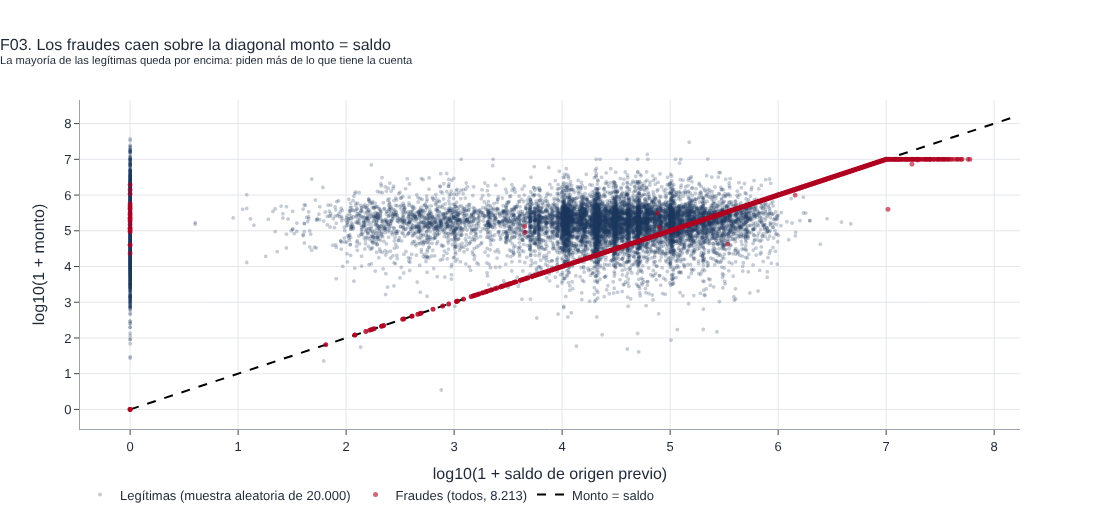

Figura guardada en outputs/figures/F03_diagonal_vaciamiento.html y .png


In [15]:
# 7.4 Figura F03: diagonal de vaciamiento (monto frente a saldo de origen, escala log10(1 + x))
muestra_lg = lg.sample(n=20_000, random_state=SEED)
fig = go.Figure()
fig.add_scattergl(x=np.log10(1 + muestra_lg["oldbalanceOrg"]), y=np.log10(1 + muestra_lg["amount"]), mode="markers",
                  name="Legítimas (muestra aleatoria de 20.000)", marker=dict(color=COLOR_LEGIT, size=4, opacity=0.25),
                  hovertemplate="saldo %{customdata[0]:,.0f}<br>monto %{customdata[1]:,.0f}<extra>Legítima</extra>",
                  customdata=muestra_lg[["oldbalanceOrg", "amount"]])
fig.add_scattergl(x=np.log10(1 + fr["oldbalanceOrg"]), y=np.log10(1 + fr["amount"]), mode="markers",
                  name=f"Fraudes (todos, {f_int(len(fr))})", marker=dict(color=COLOR_FRAUD, size=5, opacity=0.6),
                  hovertemplate="saldo %{customdata[0]:,.0f}<br>monto %{customdata[1]:,.0f}<extra>Fraude</extra>",
                  customdata=fr[["oldbalanceOrg", "amount"]])
fig.add_scatter(x=[0, 8.2], y=[0, 8.2], mode="lines", name="Monto = saldo", line=dict(color="black", dash="dash"))
fig.update_layout(title="F03. Los fraudes caen sobre la diagonal monto = saldo<br><sup>La mayoría de las legítimas queda por encima: piden más de lo que tiene la cuenta</sup>", margin=dict(t=100, b=90),
                  xaxis_title="log10(1 + saldo de origen previo)", yaxis_title="log10(1 + monto)", height=560,
                  legend=dict(orientation="h", y=-0.15))
fig.show()
guardar_fig(fig, "F03_diagonal_vaciamiento")

In [16]:
# 7.5 Valores extremos de monto según el criterio de Tukey (sobre el subespacio de riesgo completo)
q1, q3 = df_riesgo["amount"].quantile([0.25, 0.75])
lim_tukey = q3 + 1.5 * (q3 - q1)
cola_fr, cola_lg = (fr["amount"] > lim_tukey).mean(), (lg["amount"] > lim_tukey).mean()
monto_cola_fr = fr.loc[fr["amount"] > lim_tukey, "amount"].sum() / fr["amount"].sum()
print(f"Límite superior de Tukey (Q3 + 1,5·IQR): {f_num(lim_tukey)} u.m.")
print(f"Superan el límite el {f_pct(cola_fr)} de los fraudes ({f_int((fr['amount'] > lim_tukey).sum())}) y el {f_pct(cola_lg)} de las legítimas.")
print(f"Esa cola concentra el {f_pct(monto_cola_fr, 1)} del monto defraudado.")
print("Decisión 10: los valores extremos no son errores de carga (no hay negativos ni montos imposibles) y concentran el riesgo; "
      "se conservan todos y se atenúa su escala con log10(1 + x) en el modelado.")

Límite superior de Tukey (Q3 + 1,5·IQR): 642.517,64 u.m.
Superan el límite el 41,92% de los fraudes (3.443) y el 7,95% de las legítimas.
Esa cola concentra el 91,8% del monto defraudado.
Decisión 10: los valores extremos no son errores de carga (no hay negativos ni montos imposibles) y concentran el riesgo; se conservan todos y se atenúa su escala con log10(1 + x) en el modelado.


,Categoría,Fraudes,% de las excepciones
0,Tramo de 10.000.000 desde una cuenta con más saldo,145,81.0
1,Cuenta de origen con saldo 0,25,14.0
2,Residual,9,5.0


Saldo mínimo de origen en los tramos de 10.000.000: 10.175.598 u.m. (siempre mayor al monto).

Los 9 casos residuales, uno por uno (no se los fuerza en una categoría):


,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,monto / saldo,subtipo
1911,1,CASH_OUT,"132,842.64","4,499.08",0.00,0.00,"132,842.64",29.53,Monto mayor que el saldo
60853,9,TRANSFER,"994,453.20","1,437,370.87","442,917.67","194,812.76","665,743.67",0.69,Vaciamiento parcial
217978,13,TRANSFER,"123,194.95","79,466.45",0.00,"535,933.16","263,908.84",1.55,Monto mayor que el saldo
377151,17,CASH_OUT,"42,062.82","340,830.43","298,767.61","398,931.35","678,419.64",0.12,Vaciamiento parcial
408955,18,CASH_OUT,"314,251.58","75,956.47",0.00,"7,962,205.25","8,276,456.84",4.14,Monto mayor que el saldo
559979,22,CASH_OUT,"89,571.46","4,505.60",0.00,"1,929,428.01","2,018,999.47",19.88,Monto mayor que el saldo
5996409,425,TRANSFER,"9,585,040.37","19,585,040.37","19,585,040.37",0.00,0.00,0.49,Remanente: saldo − monto = 10.000.000
6281484,646,TRANSFER,"399,045.08","10,399,045.08","10,399,045.08",0.00,0.00,0.04,Remanente: saldo − monto = 10.000.000
6362462,730,TRANSFER,"7,316,255.05","17,316,255.05","17,316,255.05",0.00,0.00,0.42,Remanente: saldo − monto = 10.000.000


Subtipos residuales: Monto mayor que el saldo: 4; Remanente: saldo − monto = 10.000.000: 3; Vaciamiento parcial: 2.


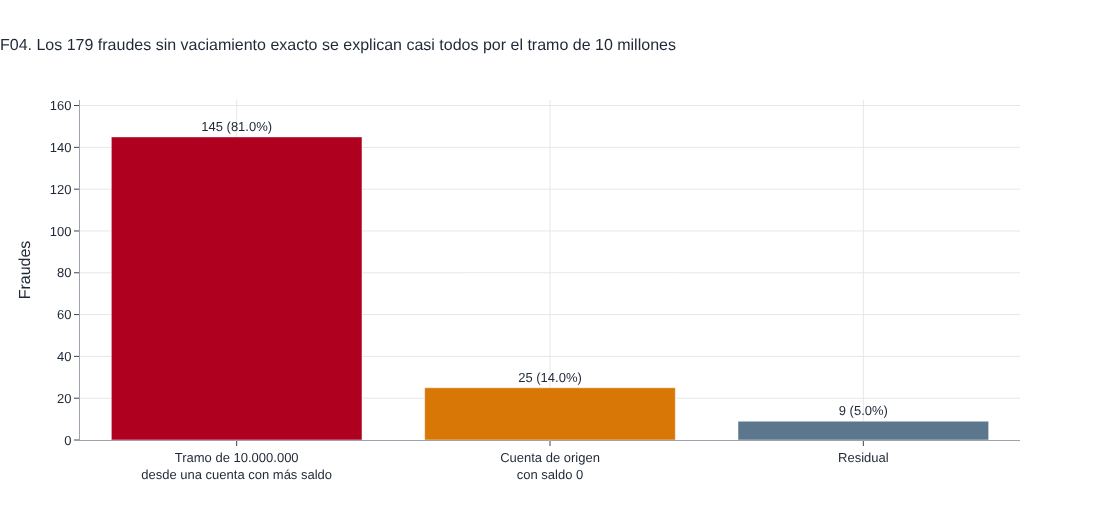

Figura guardada en outputs/figures/F04_anatomia_excepciones.html y .png


In [17]:
# 7.6 Anatomía de los fraudes que no vacían exactamente el saldo
exc = fr[~df_riesgo.loc[fr.index, "vaciamiento_exacto"]].copy()
exc["categoría"] = np.select(
    [exc["amount"] == TOPE, exc["oldbalanceOrg"] == 0],
    ["Tramo de 10.000.000 desde una cuenta con más saldo", "Cuenta de origen con saldo 0"],
    default="Residual")
anat = exc["categoría"].value_counts().rename_axis("Categoría").reset_index(name="Fraudes")
anat["% de las excepciones"] = anat["Fraudes"] / len(exc) * 100
display(anat.style.format({"% de las excepciones": "{:.1f}"}))
if (exc["categoría"] == "Tramo de 10.000.000 desde una cuenta con más saldo").any():
    print(f"Saldo mínimo de origen en los tramos de 10.000.000: "
          f"{f_num(exc.loc[exc['amount'] == TOPE, 'oldbalanceOrg'].min(), 0)} u.m. (siempre mayor al monto).")
resid = exc[exc["categoría"] == "Residual"][["step", "type", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]]
resid = resid.assign(**{"monto / saldo": resid["amount"] / resid["oldbalanceOrg"]})
resid["subtipo"] = np.select(
    [resid["amount"] > resid["oldbalanceOrg"], np.isclose(resid["oldbalanceOrg"] - resid["amount"], TOPE)],
    ["Monto mayor que el saldo", "Remanente: saldo − monto = 10.000.000"], default="Vaciamiento parcial")
print(f"\nLos {len(resid)} casos residuales, uno por uno (no se los fuerza en una categoría):")
display(resid.style.format({c: "{:,.2f}" for c in resid.columns if c not in ("step", "type", "subtipo")}))
print("Subtipos residuales: " + "; ".join(f"{k}: {v}" for k, v in resid["subtipo"].value_counts().items()) + ".")

fig = go.Figure(go.Bar(x=anat["Categoría"].str.replace(" desde una cuenta con más saldo", "<br>desde una cuenta con más saldo").str.replace("Cuenta de origen con saldo 0", "Cuenta de origen<br>con saldo 0"), y=anat["Fraudes"], marker_color=[COLOR_FRAUD, COLOR_ACCENT, COLOR_NEUTRAL][:len(anat)],
                       text=[f"{v} ({p:.1f}%)" for v, p in zip(anat["Fraudes"], anat["% de las excepciones"])], textposition="outside"))
fig.update_layout(title=f"F04. Los {len(exc)} fraudes sin vaciamiento exacto se explican casi todos por el tramo de 10 millones",
                  yaxis_title="Fraudes", height=440)
fig.show()
guardar_fig(fig, "F04_anatomia_excepciones")

In [18]:
# 7.7 El monto de 10.000.000: cuándo es señal de fraude y cuándo no
df_riesgo["monto_10m"] = df_riesgo["amount"] == TOPE
df_riesgo["saldo_cubre_10m"] = df_riesgo["oldbalanceOrg"] >= TOPE
t10 = pd.crosstab([df_riesgo["monto_10m"], df_riesgo["saldo_cubre_10m"]], df_riesgo["isFraud"])
t10.columns = ["Legítimas", "Fraudes"]
display(t10.loc[True])
dia = (df_riesgo["step"] - 1) // 24 + 1
lg10 = df_riesgo[df_riesgo["monto_10m"] & (df_riesgo["isFraud"] == 0)]
por_dia = lg10.groupby(dia[lg10.index]).size()
print(f"Las {f_int(len(lg10))} legítimas de exactamente 10.000.000 son todas TRANSFER sin saldo suficiente "
      f"({f_pct((lg10['amount'] > lg10['oldbalanceOrg']).mean(), 0)} con monto mayor al saldo) y se concentran en pocos días: "
      + ", ".join(f"día {d}: {f_int(n)}" for d, n in por_dia.sort_values(ascending=False).head(4).items()) + ".")
print("Decisión 5: el monto de 10.000.000 por sí solo no es una señal estable; sí lo es la combinación 'tramo de 10.000.000 desde una cuenta "
      "cuyo saldo lo cubre', que en todo el período no presenta legítimas. Se modela esa combinación y no el monto aislado.")

,Legítimas,Fraudes
saldo_cubre_10m,,
False,2920,0
True,0,287


Las 2.920 legítimas de exactamente 10.000.000 son todas TRANSFER sin saldo suficiente (100% con monto mayor al saldo) y se concentran en pocos días: día 13: 2.113, día 14: 727, día 16: 48, día 15: 12.
Decisión 5: el monto de 10.000.000 por sí solo no es una señal estable; sí lo es la combinación 'tramo de 10.000.000 desde una cuenta cuyo saldo lo cubre', que en todo el período no presenta legítimas. Se modela esa combinación y no el monto aislado.


## Sección 8. Dimensión temporal
La hora del día se obtiene como `step mod 24`; PaySim no documenta a qué hora del reloj corresponde el primer *step*, por lo que la hora es relativa a la simulación. El análisis se hace dentro del subespacio de riesgo, que es donde se modela.

In [19]:
# 8.1 Tasa de fraude por hora y por franja horaria, con intervalos de Wilson
df_riesgo["hora"] = (df_riesgo["step"] % 24).astype("int8")
df_riesgo["dia"] = ((df_riesgo["step"] - 1) // 24 + 1).astype("int8")
hora = df_riesgo.groupby("hora").agg(operaciones=("isFraud", "size"), fraudes=("isFraud", "sum")).reset_index()
hora["tasa"] = hora["fraudes"] / hora["operaciones"]
hora[["ic_inf", "ic_sup"]] = [wilson(k, n) for k, n in zip(hora["fraudes"], hora["operaciones"])]

franjas = pd.cut(df_riesgo["hora"], bins=[-1, 5, 11, 17, 23], labels=["00 a 05 h", "06 a 11 h", "12 a 17 h", "18 a 23 h"])
fr_tab = df_riesgo.groupby(franjas, observed=True).agg(operaciones=("isFraud", "size"), fraudes=("isFraud", "sum"))
fr_tab["% de los fraudes"] = fr_tab["fraudes"] / N_FRAUDE * 100
fr_tab["tasa de fraude (%)"] = fr_tab["fraudes"] / fr_tab["operaciones"] * 100
fr_tab.to_csv(TAB_DIR / "tabla_fraude_por_franja.csv")
display(fr_tab.style.format({"operaciones": "{:,}", "fraudes": "{:,}", "% de los fraudes": "{:.1f}", "tasa de fraude (%)": "{:.3f}"}))

h_max = hora.loc[hora["tasa"].idxmax()]
t_mad, t_tar = fr_tab["tasa de fraude (%)"].iloc[0], fr_tab["tasa de fraude (%)"].iloc[2]
print(f"Los fraudes se reparten de manera casi uniforme entre franjas ({f_num(fr_tab['% de los fraudes'].min(), 1)}% a "
      f"{f_num(fr_tab['% de los fraudes'].max(), 1)}%), mientras que el volumen legítimo cae de noche.")
print(f"Resultado: la tasa de fraude en la franja de 00 a 05 h es {f_num(t_mad, 2)}%, {f_num(t_mad / t_tar, 0)} veces la de 12 a 17 h ({f_num(t_tar, 3)}%). "
      f"El máximo horario se da a la hora {int(h_max['hora'])}: {f_pct(h_max['tasa'], 1)} de fraude "
      f"({f_int(h_max['fraudes'])} de {f_int(h_max['operaciones'])} operaciones; IC 95%: {f_pct(h_max['ic_inf'], 1)} a {f_pct(h_max['ic_sup'], 1)}).")
print("Decisión 13: la hora aporta información (el riesgo relativo cambia de forma marcada a lo largo del día) y se incorpora "
      "con codificación cíclica hora_sen = sen(2πh/24) y hora_cos = cos(2πh/24), para que las 23 h y las 0 h queden contiguas.")

,operaciones,fraudes,% de los fraudes,tasa de fraude (%)
hora,,,,
00 a 05 h,"28,065","1,996",24.3,7.112
06 a 11 h,"519,040","2,094",25.5,0.403
12 a 17 h,"1,223,677","2,077",25.3,0.170
18 a 23 h,"999,627","2,046",24.9,0.205


Los fraudes se reparten de manera casi uniforme entre franjas (24,3% a 25,5%), mientras que el volumen legítimo cae de noche.
Resultado: la tasa de fraude en la franja de 00 a 05 h es 7,11%, 42 veces la de 12 a 17 h (0,170%). El máximo horario se da a la hora 5: 57,9% de fraude (366 de 632 operaciones; IC 95%: 54,0% a 61,7%).
Decisión 13: la hora aporta información (el riesgo relativo cambia de forma marcada a lo largo del día) y se incorpora con codificación cíclica hora_sen = sen(2πh/24) y hora_cos = cos(2πh/24), para que las 23 h y las 0 h queden contiguas.


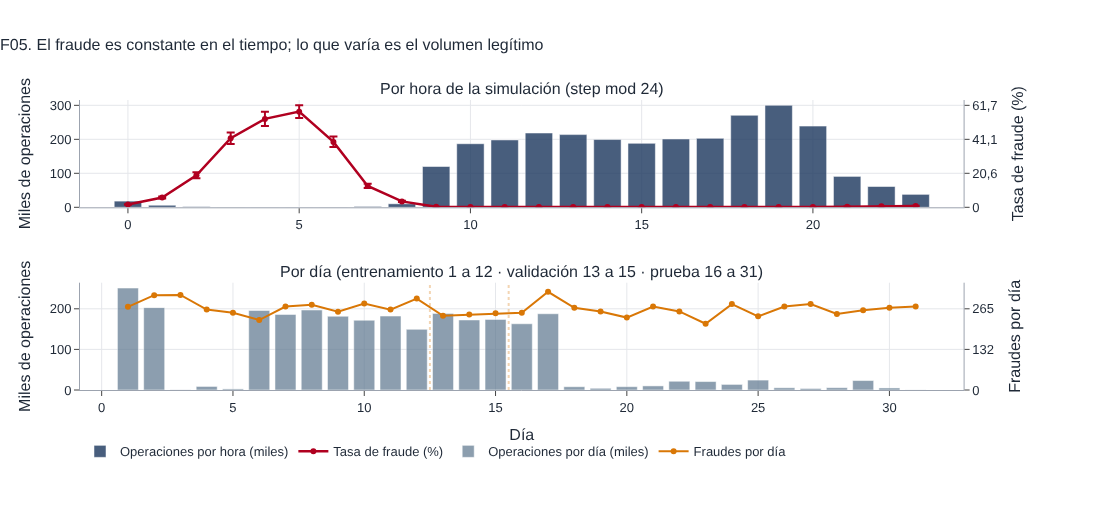

Figura guardada en outputs/figures/F05_patron_temporal.html y .png
Volumen medio diario: 150.993 operaciones en los días 1 a 15 frente a 31.594 en los días 16 a 31; fraudes medios diarios: 268 frente a 262.
Consecuencia para la evaluación: en la segunda mitad del mes el fraude se mantiene y el volumen legítimo se desploma, por lo que la prevalencia del período de prueba será mayor que la de entrenamiento. La precisión depende de la prevalencia, así que las métricas de prueba no son directamente comparables con las de validación.


In [20]:
# 8.2 Figura F05: patrón horario y evolución diaria (con el esquema de partición temporal del Notebook 2)
dia_tab = df_riesgo.groupby("dia").agg(operaciones=("isFraud", "size"), fraudes=("isFraud", "sum")).reset_index()
dia_tab["prevalencia"] = dia_tab["fraudes"] / dia_tab["operaciones"] * 100
fig = make_subplots(rows=2, cols=1, specs=[[{"secondary_y": True}], [{"secondary_y": True}]], vertical_spacing=0.26,
                    subplot_titles=("Por hora de la simulación (step mod 24)", "Por día (entrenamiento 1 a 12 · validación 13 a 15 · prueba 16 a 31)"))
fig.add_bar(x=hora["hora"], y=hora["operaciones"] / 1e3, name="Operaciones por hora (miles)", marker_color=COLOR_LEGIT, opacity=0.8, row=1, col=1)
fig.add_scatter(x=hora["hora"], y=hora["tasa"] * 100, name="Tasa de fraude (%)", mode="lines+markers", line=dict(color=COLOR_FRAUD, width=2.5),
                error_y=dict(type="data", symmetric=False, array=(hora["ic_sup"] - hora["tasa"]) * 100, arrayminus=(hora["tasa"] - hora["ic_inf"]) * 100),
                row=1, col=1, secondary_y=True)
fig.add_bar(x=dia_tab["dia"], y=dia_tab["operaciones"] / 1e3, name="Operaciones por día (miles)", marker_color=COLOR_NEUTRAL, opacity=0.7, row=2, col=1)
fig.add_scatter(x=dia_tab["dia"], y=dia_tab["fraudes"], name="Fraudes por día", mode="lines+markers", line=dict(color=COLOR_ACCENT), row=2, col=1, secondary_y=True)
for xv in (12.5, 15.5):
    fig.add_shape(type="line", x0=xv, x1=xv, xref="x2", y0=0, y1=1, yref="y3 domain", line=dict(dash="dot", color=COLOR_ACCENT, width=2))
fig.update_xaxes(title_text="Día", row=2, col=1)
fig.update_yaxes(title_text="Miles de operaciones", secondary_y=False)
fig.update_yaxes(title_text="Tasa de fraude (%)", secondary_y=True, showgrid=False, rangemode="tozero", row=1, col=1)
fig.update_yaxes(title_text="Fraudes por día", secondary_y=True, showgrid=False, rangemode="tozero", row=2, col=1)
fig.update_layout(title="F05. El fraude es constante en el tiempo; lo que varía es el volumen legítimo", height=880, margin=dict(t=100, b=130),
                  legend=dict(orientation="h", y=-0.16))
fig.show()
guardar_fig(fig, "F05_patron_temporal")
a, b = dia_tab[dia_tab["dia"] <= 15], dia_tab[dia_tab["dia"] >= 16]
print(f"Volumen medio diario: {f_int(a['operaciones'].mean())} operaciones en los días 1 a 15 frente a {f_int(b['operaciones'].mean())} en los días 16 a 31; "
      f"fraudes medios diarios: {f_num(a['fraudes'].mean(), 0)} frente a {f_num(b['fraudes'].mean(), 0)}.")
print("Consecuencia para la evaluación: en la segunda mitad del mes el fraude se mantiene y el volumen legítimo se desploma, "
      "por lo que la prevalencia del período de prueba será mayor que la de entrenamiento. La precisión depende de la prevalencia, "
      "así que las métricas de prueba no son directamente comparables con las de validación.")

## Sección 9. Cuentas de destino y regla vigente
### 9.1 ¿Las cuentas que reciben fraude son "de un solo uso"?
Una versión anterior del trabajo afirmaba que el 99,46% de las cuentas receptoras de fraude "se usa una sola vez y jamás vuelve a registrar actividad". Esa proporción contaba solo las operaciones **fraudulentas** recibidas. La celda siguiente mide la actividad **total** de esas cuentas en todo el período, con la misma base para fraudes y legítimas.

In [21]:
# 9.1 Actividad de las cuentas de destino: fraude frente a legítimas, sobre la misma base
total_recibido = df["nameDest"].value_counts()
dest_fr = fr["nameDest"].unique(); dest_lg = lg["nameDest"].unique()
fraudes_por_dest = fr["nameDest"].value_counts()

primer_fraude = fr.groupby("nameDest")["step"].min().rename("primer_fraude")
act = df.loc[df["nameDest"].isin(dest_fr), ["nameDest", "step"]].join(primer_fraude, on="nameDest")
con_previa = (act["step"] < act["primer_fraude"]).groupby(act["nameDest"]).any()
con_posterior = (act["step"] > act["primer_fraude"]).groupby(act["nameDest"]).any()

# Para cada operación de riesgo: ¿su destino ya había recibido alguna operación en una hora anterior?
primer_step_dest = df.groupby("nameDest")["step"].min()
op_con_historia = df_riesgo["step"].to_numpy() > primer_step_dest.reindex(df_riesgo["nameDest"]).to_numpy()
hist_fr, hist_lg = op_con_historia[df_riesgo["isFraud"].to_numpy() == 1].mean(), op_con_historia[df_riesgo["isFraud"].to_numpy() == 0].mean()

mulas = pd.DataFrame({
    "Indicador": ["Cuentas de destino distintas",
                  "Reciben exactamente 1 operación fraudulenta",
                  "Reciben exactamente 1 operación en todo el período (cualquier tipo)",
                  "Tenían actividad antes del primer fraude recibido",
                  "Registran actividad después del primer fraude recibido",
                  "Operaciones cuyo destino ya tenía actividad en horas anteriores"],
    "Destinos de fraude": [f_int(len(dest_fr)), f_pct((fraudes_por_dest == 1).mean()), f_pct((total_recibido.loc[dest_fr] == 1).mean()),
                           f_pct(con_previa.mean()), f_pct(con_posterior.mean()), f_pct(hist_fr)],
    "Destinos de legítimas": [f_int(len(dest_lg)), "—", f_pct((total_recibido.loc[dest_lg] == 1).mean()), "—", "—", f_pct(hist_lg)],
})
display(mulas)
print(f"Lectura: el {f_pct((fraudes_por_dest == 1).mean())} de las cuentas receptoras recibe un único fraude, pero solo el "
      f"{f_pct((total_recibido.loc[dest_fr] == 1).mean(), 1)} recibe una única operación en todo el mes; el {f_pct(con_posterior.mean(), 1)} sigue "
      "operando después. La afirmación de 'cuentas de un solo uso' no se sostiene: lo que se observa es que el atacante "
      "no repite destino para distintas víctimas.")
print(f"Lo que sí se sostiene, y motiva los atributos de historial del Notebook 2: el destino de una operación fraudulenta tiene actividad "
      f"previa en el {f_pct(hist_fr, 1)} de los casos, frente al {f_pct(hist_lg, 1)} en las legítimas. El historial previo del destino es "
      "un factor que reduce el riesgo, no una prueba de cuenta mula. PaySim no informa la fecha de alta de las cuentas, por lo que "
      "no puede afirmarse que sean 'recién creadas'.")

,Indicador,Destinos de fraude,Destinos de legítimas
0,Cuentas de destino distintas,8.169,506.458
1,Reciben exactamente 1 operación fraudulenta,"99,46%",—
2,Reciben exactamente 1 operación en todo el per...,"32,72%","12,36%"
3,Tenían actividad antes del primer fraude recibido,"36,39%",—
4,Registran actividad después del primer fraude ...,"52,65%",—
5,Operaciones cuyo destino ya tenía actividad en...,"36,73%","84,89%"


Lectura: el 99,46% de las cuentas receptoras recibe un único fraude, pero solo el 32,7% recibe una única operación en todo el mes; el 52,7% sigue operando después. La afirmación de 'cuentas de un solo uso' no se sostiene: lo que se observa es que el atacante no repite destino para distintas víctimas.
Lo que sí se sostiene, y motiva los atributos de historial del Notebook 2: el destino de una operación fraudulenta tiene actividad previa en el 36,7% de los casos, frente al 84,9% en las legítimas. El historial previo del destino es un factor que reduce el riesgo, no una prueba de cuenta mula. PaySim no informa la fecha de alta de las cuentas, por lo que no puede afirmarse que sean 'recién creadas'.


In [22]:
# 9.2 Auditoría de la regla vigente isFlaggedFraud
flag = df[df["isFlaggedFraud"] == 1]
transfer = df[df["type"] == "TRANSFER"]
n_doc = int((transfer["amount"] > 200_000).sum())
tp_flag = int(flag["isFraud"].sum())
monto_fraude_total = fr["amount"].sum()
print(f"Alertas de la regla en 31 días: {len(flag)} (todas TRANSFER: {bool((flag['type'] == 'TRANSFER').all())}); fraudes entre ellas: {tp_flag}.")
print(f"Si la regla fuera la documentada (TRANSFER con monto > 200.000 u.m.), habría marcado {f_int(n_doc)} operaciones. "
      "La bandera observada es mucho más restrictiva: no puede reconstruirse a partir del monto.")
print(f"Rasgos comunes de las {len(flag)} alertas: saldo de origen sin cambios = {bool((flag['oldbalanceOrg'] == flag['newbalanceOrig']).all())}, "
      f"saldos de destino en 0 = {bool(((flag['oldbalanceDest'] == 0) & (flag['newbalanceDest'] == 0)).all())}, "
      f"montos entre {f_num(flag['amount'].min(), 0)} y {f_num(flag['amount'].max(), 0)} u.m.")
print(f"Sensibilidad de la regla: {f_pct(tp_flag / N_FRAUDE, 3)} de los fraudes; capital cubierto: "
      f"{f_pct(flag.loc[flag['isFraud'] == 1, 'amount'].sum() / monto_fraude_total)} del monto defraudado "
      f"({f_num(monto_fraude_total / 1e6, 1)} millones de u.m. en total).")
print("La regla vigente es precisa pero prácticamente ciega: es la línea de base a superar.")

Alertas de la regla en 31 días: 16 (todas TRANSFER: True); fraudes entre ellas: 16.
Si la regla fuera la documentada (TRANSFER con monto > 200.000 u.m.), habría marcado 409.110 operaciones. La bandera observada es mucho más restrictiva: no puede reconstruirse a partir del monto.
Rasgos comunes de las 16 alertas: saldo de origen sin cambios = True, saldos de destino en 0 = True, montos entre 353.874 y 10.000.000 u.m.
Sensibilidad de la regla: 0,195% de los fraudes; capital cubierto: 0,65% del monto defraudado (12.056,4 millones de u.m. en total).
La regla vigente es precisa pero prácticamente ciega: es la línea de base a superar.


## Sección 10. Registro de decisiones de curación y exportación de la base curada
La tabla se arma con las cifras calculadas en las celdas anteriores, de modo que no puede quedar desactualizada respecto de los resultados.

In [23]:
# 10.1 Registro de decisiones (las cifras provienen de las variables calculadas arriba)
lg_cero = (lg["oldbalanceOrg"] == 0).mean(); fr_cero = (fr["oldbalanceOrg"] == 0).mean()
decisiones = pd.DataFrame([
    (1, "Valores nulos", f"{f_int(nulos.sum())} nulos en {f_int(N_TOTAL)} filas.", "Sin imputación ni eliminación."),
    (2, "Duplicados", f"{dup_exactos} exactos y {dup_clave} por clave (step, origen, destino, monto).", "Se conservan todas las filas."),
    (3, "Precisión numérica", f"{f_pct(pct_distorsion, 1)} de los montos pierde centavos en float32.", "Montos y saldos en float64; comparaciones al centavo."),
    (4, "Montos en 0", f"{n_monto0} operaciones, {n_monto0_fr} de ellas fraude.", "Se conservan: son intentos sobre cuentas sin saldo."),
    (5, "Monto de 10.000.000", f"{n_fr_tope} fraudes y {f_int(n_lg_tope)} legítimas en ese valor; {f_int(n_lg_sobre)} legítimas lo superan.",
     "No es un límite del sistema. Se modela 'tramo de 10 M desde cuenta con saldo suficiente', no el monto aislado."),
    (6, "Destinos comercio (M)", f"{f_int(len(dest_m))} PAYMENT con saldos de destino siempre en 0; {int(dest_m['isFraud'].sum())} fraudes.",
     "Ceros estructurales: no se imputan; bandera dest_es_comerciante."),
    (7, "Saldo de origen en 0", f"{f_pct(lg_cero, 1)} de las legítimas y {f_pct(fr_cero, 2)} de los fraudes de riesgo.", "No se imputa; bandera emisor_sin_saldo."),
    (8, "Saldo insuficiente", f"Monto > saldo en {f_num(te.loc[True, '% de legítimas'], 1)}% de las legítimas y {f_num(te.loc[True, '% de fraudes'], 2)}% de los fraudes.",
     "Bandera ex ante monto_excede_saldo; explica la aparente inconsistencia contable."),
    (9, "Saldos posteriores", "Son resultado de la operación (en fraude el saldo final es casi siempre 0).", "newbalanceOrig y newbalanceDest se excluyen como predictores."),
    (10, "Valores extremos", f"La cola de Tukey reúne el {f_pct(cola_fr, 1)} de los fraudes y el {f_pct(monto_cola_fr, 1)} del monto defraudado.",
     "Se conservan; transformación log10(1 + x)."),
    (11, "Tipos sin fraude", f"PAYMENT, CASH_IN y DEBIT: 0 fraudes en {f_int(N_TOTAL - N_RIESGO)} operaciones.",
     "Se modela solo TRANSFER y CASH_OUT; los demás tipos se conservan para construir historial."),
    (12, "Firma de vaciamiento", f"{f_pct(VAC_FR / N_FRAUDE)} de los fraudes y {VAC_LG} legítimas.", "Bandera marca_vaciamiento y razón continua monto/saldo."),
    (13, "Hora del día", f"Tasa de fraude {f_num(t_mad / t_tar, 0)} veces mayor de 00 a 05 h que de 12 a 17 h.", "Codificación cíclica hora_sen y hora_cos."),
    (14, "Historial del destino", f"Destino con actividad previa: {f_pct(hist_fr, 1)} en fraude y {f_pct(hist_lg, 1)} en legítimas.",
     "Historial causal de 168 h por destino (ventana [t − 168 h, t))."),
], columns=["N°", "Aspecto", "Evidencia", "Decisión"])
decisiones.to_csv(TAB_DIR / "registro_decisiones_eda.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(decisiones.set_index("N°"))

,Aspecto,Evidencia,Decisión
N°,,,
1,Valores nulos,0 nulos en 6.362.620 filas.,Sin imputación ni eliminación.
2,Duplicados,"0 exactos y 0 por clave (step, origen, destino, monto).",Se conservan todas las filas.
3,Precisión numérica,"20,5% de los montos pierde centavos en float32.",Montos y saldos en float64; comparaciones al centavo.
4,Montos en 0,"16 operaciones, 16 de ellas fraude.",Se conservan: son intentos sobre cuentas sin saldo.
5,Monto de 10.000.000,287 fraudes y 2.920 legítimas en ese valor; 2.443 legítimas lo superan.,"No es un límite del sistema. Se modela 'tramo de 10 M desde cuenta con saldo suficiente', no el monto aislado."
6,Destinos comercio (M),2.151.495 PAYMENT con saldos de destino siempre en 0; 0 fraudes.,Ceros estructurales: no se imputan; bandera dest_es_comerciante.
7,Saldo de origen en 0,"47,4% de las legítimas y 0,50% de los fraudes de riesgo.",No se imputa; bandera emisor_sin_saldo.
8,Saldo insuficiente,"Monto > saldo en 90,1% de las legítimas y 0,35% de los fraudes.",Bandera ex ante monto_excede_saldo; explica la aparente inconsistencia contable.
9,Saldos posteriores,Son resultado de la operación (en fraude el saldo final es casi siempre 0).,newbalanceOrig y newbalanceDest se excluyen como predictores.


In [24]:
# 10.2 Exportación de la base curada (Parquet, orden cronológico estable)
t0 = time.perf_counter()
curada = df[COLUMNAS].copy()
curada["dest_es_comerciante"] = curada["nameDest"].str.startswith("M").astype("int8")
curada = curada.sort_values("step", kind="mergesort").reset_index(drop=True)
assert len(curada) == N_TOTAL and int(curada["isFraud"].sum()) == N_FRAUDE
ruta_parquet = DATA_PROC_DIR / "base_curada_paysim.parquet"
curada.to_parquet(ruta_parquet, index=False, engine="pyarrow", compression="snappy")
print(f"Base curada: {ruta_rel(ruta_parquet)} | {f_int(len(curada))} filas x {curada.shape[1]} columnas | "
      f"{f_num(ruta_parquet.stat().st_size / 2**20, 1)} MB | {f_num(time.perf_counter() - t0, 1)} s")
print("Contenido: las 11 columnas originales (montos en float64) más dest_es_comerciante. Los atributos del modelo se construyen "
      "en el Notebook 2 a partir de esta base, para que toda transformación quede junto al modelo que la usa.")

Base curada: datos/processed/base_curada_paysim.parquet | 6.362.620 filas x 12 columnas | 257,8 MB | 2,8 s
Contenido: las 11 columnas originales (montos en float64) más dest_es_comerciante. Los atributos del modelo se construyen en el Notebook 2 a partir de esta base, para que toda transformación quede junto al modelo que la usa.


## Sección 11. Conclusiones y puente hacia el Notebook 2

**Calidad.** La base no tiene nulos, duplicados ni valores imposibles. El único riesgo técnico es guardar montos en `float32`, que altera el centavo del 20,5% de las operaciones; por eso se conserva `float64`.

**Dónde está el riesgo.** Todo el fraude ocurre en `TRANSFER` y `CASH_OUT`: 2.770.409 operaciones con prevalencia de 0,296%, un fraude cada 337.

**Cómo opera el fraude simulado.** El 97,82% de los fraudes vacía la cuenta al centavo y ninguna legítima lo hace. Las 179 excepciones se explican: 145 tramos de 10.000.000, 25 cuentas con saldo 0 y 9 casos residuales. Además, el 90,10% de las legítimas pide más que el saldo registrado, frente al 0,35% de los fraudes.

**Tres ideas previas corregidas.** (1) La inconsistencia contable no es asincronía: el simulador lleva el saldo a 0 y la discrepancia cae de 90,51% a 0,41%. (2) El monto de 10.000.000 no es exclusivo del fraude: hay 2.920 legítimas en ese valor, casi todas los días 13 (2.113) y 14 (727), por lo que se modela el tramo con saldo suficiente. (3) Las cuentas receptoras no son de un solo uso: solo el 32,72% recibe una única operación, aunque tienen menos actividad previa (36,7% frente a 84,9%).

**Tiempo.** El fraude es estable (268 y 262 casos diarios por quincena) y el volumen legítimo cae de 150.993 a 31.594 operaciones diarias. Por eso la tasa de 00 a 05 h es 42 veces la de 12 a 17 h y la prevalencia de prueba será mayor.

**Línea de base.** La regla vigente emitió 16 alertas en 31 días: detectó el 0,195% de los fraudes y el 0,65% del monto.

**Implicancia.** Las regularidades más fuertes son del simulador, así que una separación casi perfecta no prueba desempeño real. El Notebook 2 compara contra una regla con esas firmas, verifica las firmas dentro del entrenamiento y simula atacantes que cambian de táctica.

**Para el Notebook 2.** Universo `TRANSFER` y `CASH_OUT`; partición cronológica días 1 a 12, 13 a 15 y 16 a 31; atributos ex ante; métricas PR-AUC y ahorro neto.

**Referencias.** Agresti y Coull (1998), Approximate is better than "exact" for interval estimation of binomial proportions, *The American Statistician* 52(2). · Brown, Cai y DasGupta (2001), Interval estimation for a binomial proportion, *Statistical Science* 16(2). · Huete (1997), *Servicios y beneficios*. · Kerby (2014), The simple difference formula: An approach to teaching nonparametric correlation, *Comprehensive Psychology* 3. · Lopez-Rojas, Elmir y Axelsson (2016), PaySim: A financial mobile money simulator for fraud detection, *28th European Modeling and Simulation Symposium*.